# Autonomous Exam Proctoring & Grading Agent: Training Notebook (v2, Colab ready)

**Run this in Google Colab:** `Runtime > Run all`, then download `exam_models.zip` from the last cell.

## What was wrong with v1 and what this version fixes

| Problem in v1 | Why it hurt | Fix in v2 |
|---|---|---|
| Grader trained on answers made by *dropping and scrambling words* | Real students write full sentences in their own words, so a correct paraphrase got a low score | Grader now uses **sentence embeddings** (meaning, not just shared words) and is trained on natural-language answers (real Mohler dataset if available, otherwise a paraphrase-based generator) |
| Grader tested on random rows | Same questions in train and test, so results looked better than reality | Test on **questions the model never saw** (GroupShuffleSplit) |
| Proctor data was too clean (two simple groups) | Output was all-or-nothing (0% or 88%) and honest students with a bad webcam looked like cheaters | **6 student types** including honest-but-nervous, honest-with-bad-camera, stealth cheaters and second-device cheaters |
| Probabilities were uncalibrated and `class_weight` distorted them | "Risk 70%" did not mean 70% | Removed class weights, added **probability calibration**, measured with Brier score and a calibration curve |
| Model could behave illogically (more tab switches, lower risk) | Hard to defend in a viva | **Monotonic constraints**: more suspicious behaviour can never lower the risk, and this is tested |
| Decision thresholds 0.4 / 0.7 were guessed | No evidence behind them | Thresholds are **chosen from the data** (target precision for HOLD, target recall for WARNING) |
| Unusual input values (for example speed variance 109) | Model had never seen such values | Input ranges saved and the agent **clips and warns** |
| Models saved with no version info | A model trained on Colab can fail to load on your laptop if scikit-learn versions differ | Versions saved and a `requirements_models.txt` is produced |

## Problem statement
| Model | Task | Type | Target |
|---|---|---|---|
| **Model A: Proctoring** | Predict whether an exam session is suspicious from behaviour logs | Classification | `suspicious` (0/1) |
| **Model B: Grader** | Predict the score of a short student answer against a reference answer | Regression | `score` (0 to 5) |

In [1]:
# ---- CONFIGURATION (change only if you need to) ----
FORCE_LSA_FALLBACK     = False   # True = skip sentence-transformers (lower quality, works offline)
TRY_DOWNLOAD_REAL_DATA = True    # try to load the real Mohler dataset
MOHLER_CSV             = "mohler.csv"   # OR upload your own CSV with columns: question, reference_answer, student_answer, score
HF_CANDIDATES          = ["nkazi/MohlerASAG", "Viswa45/ASAG"]   # HuggingFace dataset ids tried in order
EMBED_NAME             = "all-MiniLM-L6-v2"                     # sentence embedding model
SEED = 42

In [2]:
import os, re, sys, json, subprocess, warnings, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
warnings.filterwarnings("ignore")

import sklearn
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, GridSearchCV, GroupShuffleSplit, GroupKFold,
                                     StratifiedKFold, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              RandomForestRegressor, GradientBoostingRegressor)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             brier_score_loss, log_loss, confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             mean_absolute_error, mean_squared_error, r2_score)

rng = np.random.default_rng(SEED)
os.makedirs("data", exist_ok=True); os.makedirs("models", exist_ok=True)
sns.set_theme(style="whitegrid")
print("scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

scikit-learn 1.6.1 | numpy 2.1.3 | pandas 2.2.3


# PART A: Proctoring model (classification)
## 1. Data: simulated exam sessions with realistic student types
Real proctoring logs are private, so sessions are simulated. The key improvement over v1 is that **not every honest student looks the same and not every cheater looks the same**:

| Student type | Share | Label | Behaviour |
|---|---|---|---|
| honest_calm | 58% | 0 | few events, steady answering |
| honest_nervous | 12% | 0 | more tab switches and idle time, uneven speed |
| honest_bad_camera | 8% | 0 | many "face not detected" events because of lighting or camera, otherwise normal |
| cheat_blatant | 8% | 1 | many tab switches, copy-paste, extra faces, very fast |
| cheat_stealth | 8% | 1 | only mildly abnormal signals (hard to detect) |
| cheat_second_device | 6% | 1 | few tab switches but looks away (face missing), long idle time (phone or second screen) |

Extra realism: each student has a personal **intensity** multiplier (so counts vary more than a pure Poisson, called overdispersion), and 3% of labels are flipped to mimic wrong labelling.

**Definition used everywhere:** `answer_speed_variance` = **standard deviation of seconds spent per question**. The live detector must compute it the same way.
Reference exam length is about 20 questions (about 20 minutes).

In [3]:
N = 4000
TYPES = {
 "honest_calm":         dict(p=0.58, tab=2.0, face=0.8, multi=0.05, copy=0.3, idle=(110, 45), avg=(62, 15), cv=(0.15, 0.40), cheat=0),
 "honest_nervous":      dict(p=0.12, tab=4.5, face=1.5, multi=0.10, copy=0.6, idle=(150, 60), avg=(70, 18), cv=(0.25, 0.55), cheat=0),
 "honest_bad_camera":   dict(p=0.08, tab=2.5, face=5.0, multi=0.20, copy=0.3, idle=(120, 50), avg=(62, 15), cv=(0.15, 0.40), cheat=0),
 "cheat_blatant":       dict(p=0.08, tab=9.0, face=3.0, multi=1.2,  copy=4.0, idle=(190, 70), avg=(38, 12), cv=(0.40, 0.90), cheat=1),
 "cheat_stealth":       dict(p=0.08, tab=4.0, face=1.8, multi=0.3,  copy=1.5, idle=(140, 55), avg=(52, 14), cv=(0.25, 0.55), cheat=1),
 "cheat_second_device": dict(p=0.06, tab=1.5, face=4.5, multi=0.5,  copy=0.4, idle=(230, 80), avg=(55, 15), cv=(0.35, 0.70), cheat=1),
}
names = list(TYPES); probs = np.array([TYPES[n]["p"] for n in names]); probs = probs / probs.sum()
kinds = rng.choice(names, size=N, p=probs)

rows = []
for k in kinds:
    t = TYPES[k]
    z = rng.gamma(4, 0.25)                                  # personal intensity, mean 1 (overdispersion)
    avg = max(8.0, rng.normal(*t["avg"]))
    rows.append(dict(
        tab_switches=rng.poisson(t["tab"] * z),
        face_not_detected_count=rng.poisson(t["face"] * z),
        multiple_faces_count=rng.poisson(t["multi"] * z),
        avg_time_per_question=round(avg, 1),
        copy_paste_events=rng.poisson(t["copy"] * z),
        mouse_idle_time=round(max(0.0, rng.normal(*t["idle"])), 1),
        answer_speed_variance=round(avg * rng.uniform(*t["cv"]), 2),   # std dev of seconds per question
        student_type=k, suspicious=t["cheat"]))
sessions = pd.DataFrame(rows)
flip = rng.random(N) < 0.03
sessions["suspicious"] = np.where(flip, 1 - sessions["suspicious"], sessions["suspicious"])
sessions.to_csv("data/sessions.csv", index=False)
FEATURES_A = ["tab_switches", "face_not_detected_count", "multiple_faces_count", "avg_time_per_question",
              "copy_paste_events", "mouse_idle_time", "answer_speed_variance"]
print(sessions.shape, "| suspicious rate:", round(sessions["suspicious"].mean(), 3))
sessions.head()

(4000, 9) | suspicious rate: 0.237


,tab_switches,face_not_detected_count,multiple_faces_count,avg_time_per_question,copy_paste_events,mouse_idle_time,answer_speed_variance,student_type,suspicious
0,0,2,0,82.3,0,87.4,17.77,honest_bad_camera,0
1,2,1,0,57.3,0,76.0,13.10,honest_calm,0
2,14,6,1,51.2,8,161.5,27.26,cheat_blatant,1
3,11,1,0,56.3,0,252.0,29.46,honest_nervous,0
4,1,0,0,58.2,0,48.5,11.00,honest_calm,0


## 2. Exploratory data analysis

,tab_switches,face_not_detected_count,multiple_faces_count,avg_time_per_question,copy_paste_events,mouse_idle_time,answer_speed_variance
student_type,,,,,,,
cheat_blatant,8.6,3.0,1.0,37.5,3.8,187.8,24.0
cheat_second_device,1.6,4.8,0.6,55.6,0.4,229.6,29.5
cheat_stealth,4.0,1.8,0.2,52.7,1.6,139.3,21.2
honest_bad_camera,2.6,5.2,0.2,62.0,0.3,124.4,17.5
honest_calm,2.0,0.8,0.1,62.1,0.3,110.6,17.0
honest_nervous,4.6,1.4,0.1,69.9,0.6,144.7,27.7


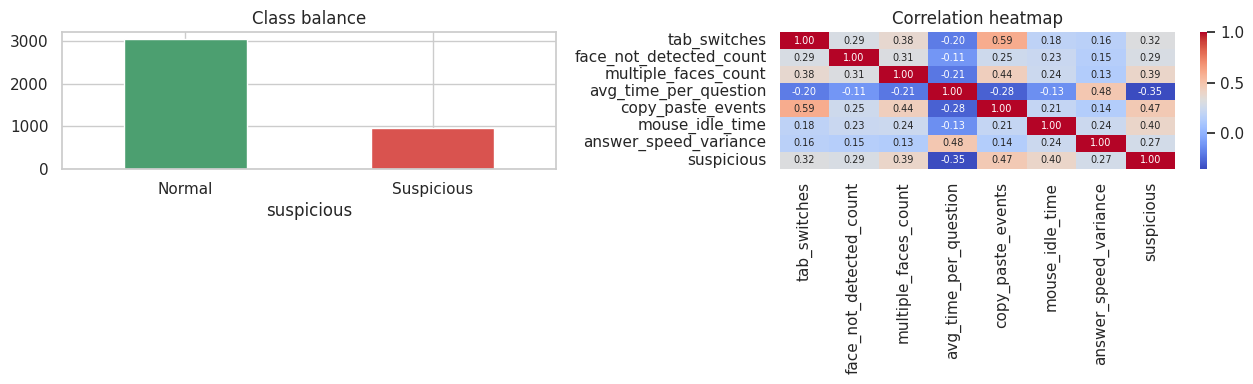

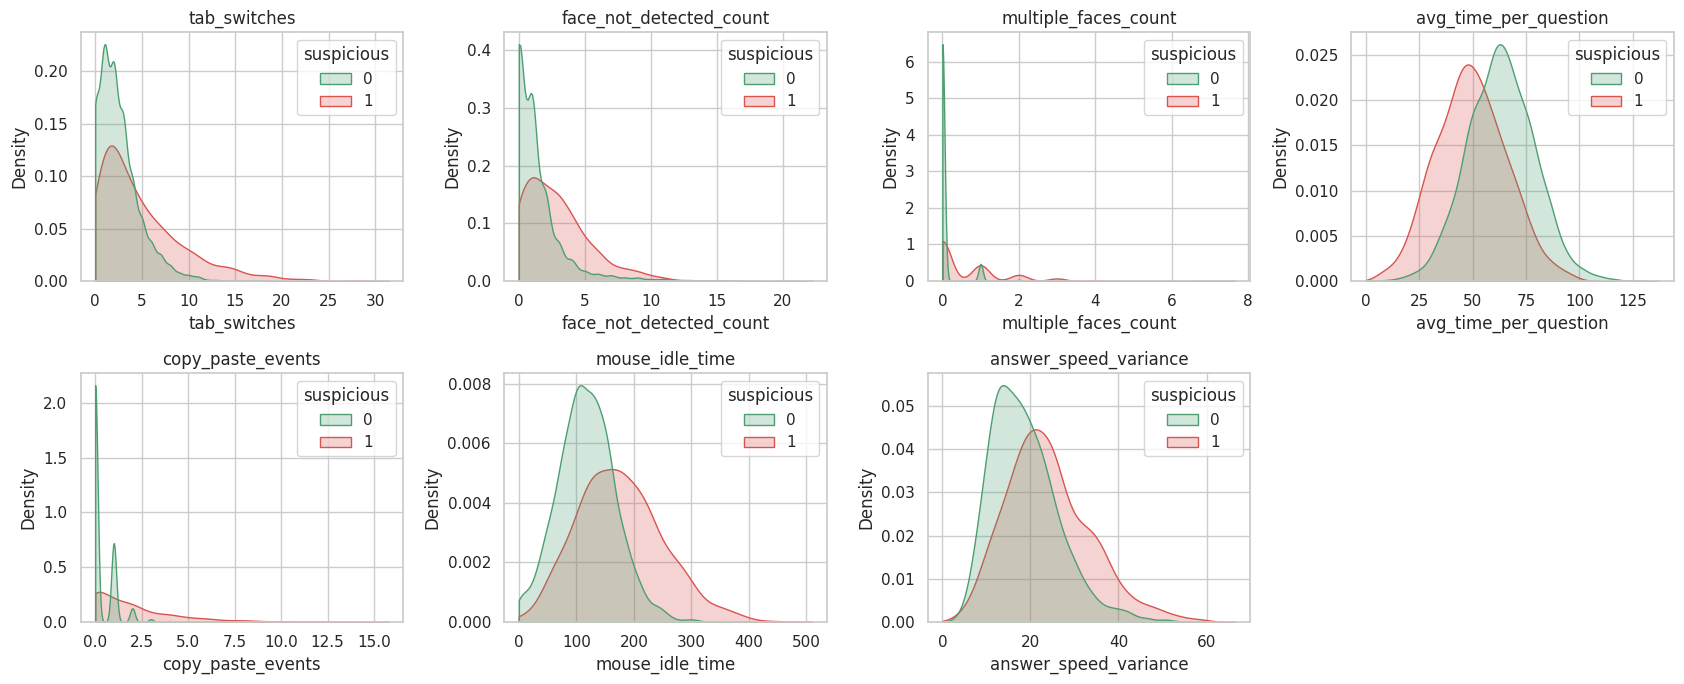

In [4]:
display(sessions.groupby("student_type")[FEATURES_A].mean().round(1))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sessions["suspicious"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color=["#4C9F70", "#D9534F"])
ax[0].set_xticklabels(["Normal", "Suspicious"], rotation=0); ax[0].set_title("Class balance")
sns.heatmap(sessions[FEATURES_A + ["suspicious"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1], annot_kws={"size": 7})
ax[1].set_title("Correlation heatmap")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for a, col in zip(axes.ravel(), FEATURES_A):
    sns.kdeplot(data=sessions, x=col, hue="suspicious", fill=True, common_norm=False, ax=a, palette=["#4C9F70", "#D9534F"], clip=(0, None))
    a.set_title(col)
axes.ravel()[-1].axis("off"); plt.tight_layout(); plt.show()

**Observation:** the two classes overlap heavily on every single feature (for example honest nervous students switch tabs as often as stealth cheaters), so no single rule works and the model has to combine signals.

## 3. Train / test split
Stratified 80/20 split. Scaling lives **inside the Pipeline** so it never sees test data.
Note: we do **not** use `class_weight="balanced"`, because it distorts predicted probabilities and the agent needs trustworthy probabilities.

In [5]:
X = sessions[FEATURES_A]; y = sessions["suspicious"]
Xtr, Xte, ytr, yte, ttr, tte = train_test_split(X, y, sessions["student_type"], test_size=0.2, stratify=y, random_state=SEED)
print("Train:", Xtr.shape, "Test:", Xte.shape, "| positive rate:", round(ytr.mean(), 3))

Train: (3200, 7) Test: (800, 7) | positive rate: 0.237


## 4. Models and comparison
* **Logistic Regression**: simple baseline.
* **Random Forest**: strong but cannot guarantee sensible behaviour, so it is a *comparison only*.
* **Gradient Boosting with monotonic constraints**: the more tab switches, copy-paste, idle time and so on, the higher the risk; the more time per question, the lower the risk. This cannot be violated, so the agent never behaves illogically.

Only Logistic Regression and monotonic Gradient Boosting are allowed to be deployed.

In [6]:
MONO = [1, 1, 1, -1, 1, 1, 1]   # same order as FEATURES_A: avg_time_per_question is -1 (faster = riskier)
def make(clf): return Pipeline([("scaler", StandardScaler()), ("clf", clf)])

def cls_metrics(model, X, y, thr=0.5):
    p = model.predict_proba(X)[:, 1]; pred = (p >= thr).astype(int)
    return dict(Accuracy=accuracy_score(y, pred), Precision=precision_score(y, pred, zero_division=0), Recall=recall_score(y, pred),
                F1=f1_score(y, pred), ROC_AUC=roc_auc_score(y, p), Brier=brier_score_loss(y, p), LogLoss=log_loss(y, p))

base_models = {
    "Logistic Regression": make(LogisticRegression(max_iter=2000)),
    "Random Forest (comparison only)": make(RandomForestClassifier(n_estimators=300, min_samples_leaf=10, random_state=SEED)),
    "Gradient Boosting (monotonic)": make(HistGradientBoostingClassifier(monotonic_cst=MONO, random_state=SEED)),
}
rows = {}
for n, m in base_models.items():
    m.fit(Xtr, ytr); rows[n] = cls_metrics(m, Xte, yte)
pd.DataFrame(rows).T.round(3)

,Accuracy,Precision,Recall,F1,ROC_AUC,Brier,LogLoss
Logistic Regression,0.912,0.875,0.737,0.800,0.918,0.073,0.272
Random Forest (comparison only),0.905,0.865,0.711,0.780,0.918,0.081,0.286
Gradient Boosting (monotonic),0.911,0.865,0.742,0.799,0.916,0.074,0.273


Brier score and LogLoss measure how *trustworthy the probabilities are* (lower is better). Accuracy alone can hide badly calibrated risk values.

## 5. Hyperparameter tuning (5-fold CV, scored by log-loss so probabilities are good)

In [7]:
grids = {
    "Logistic Regression": (make(LogisticRegression(max_iter=2000)), {"clf__C": [0.1, 1, 10]}),
    "Gradient Boosting (monotonic)": (make(HistGradientBoostingClassifier(monotonic_cst=MONO, random_state=SEED)),
                                      {"clf__learning_rate": [0.03, 0.06, 0.1], "clf__max_depth": [2, 3, 4],
                                       "clf__max_iter": [100, 200], "clf__l2_regularization": [0.0, 1.0]}),
}
tuned = {}
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, scoring="neg_log_loss", cv=5, n_jobs=-1).fit(Xtr, ytr)
    tuned[name] = gs
    print(f"{name:32s} CV log-loss = {-gs.best_score_:.4f} | {gs.best_params_}")
best_name_A = min(tuned, key=lambda k: -tuned[k].best_score_)
print("\nSelected deployable model:", best_name_A)

Logistic Regression              CV log-loss = 0.2786 | {'clf__C': 1}
Gradient Boosting (monotonic)    CV log-loss = 0.2761 | {'clf__l2_regularization': 0.0, 'clf__learning_rate': 0.1, 'clf__max_depth': 2, 'clf__max_iter': 200}

Selected deployable model: Gradient Boosting (monotonic)


## 6. Probability calibration
A calibrated model means "risk 0.7" really corresponds to about 70% of such sessions being suspicious. We compare before and after and keep the better one.

,Accuracy,Precision,Recall,F1,ROC_AUC,Brier,LogLoss
Uncalibrated,0.9088,0.8589,0.7368,0.7932,0.9151,0.0738,0.2713
Calibrated,0.9125,0.8797,0.7316,0.7989,0.9178,0.0734,0.2686


Using: calibrated model


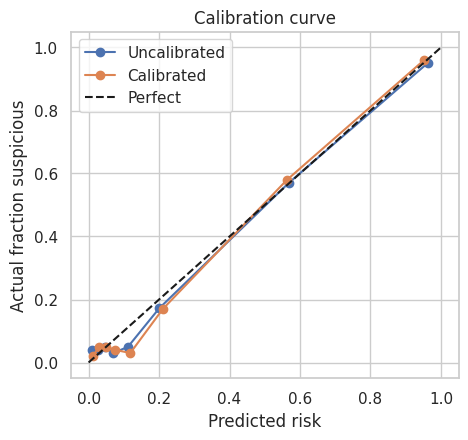

In [8]:
raw_A = tuned[best_name_A].best_estimator_
cal_A = CalibratedClassifierCV(clone(raw_A), method="sigmoid", cv=5).fit(Xtr, ytr)
cmp = pd.DataFrame({"Uncalibrated": cls_metrics(raw_A, Xte, yte), "Calibrated": cls_metrics(cal_A, Xte, yte)}).T.round(4)
display(cmp)
use_cal = cmp.loc["Calibrated", "LogLoss"] <= cmp.loc["Uncalibrated", "LogLoss"]
final_A = cal_A if use_cal else raw_A
print("Using:", "calibrated model" if use_cal else "uncalibrated model")

fig, ax = plt.subplots(figsize=(5, 4.5))
for lab, m in [("Uncalibrated", raw_A), ("Calibrated", cal_A)]:
    f, p_ = calibration_curve(yte, m.predict_proba(Xte)[:, 1], n_bins=8, strategy="quantile")
    ax.plot(p_, f, marker="o", label=lab)
ax.plot([0, 1], [0, 1], "k--", label="Perfect"); ax.set_xlabel("Predicted risk"); ax.set_ylabel("Actual fraction suspicious")
ax.set_title("Calibration curve"); ax.legend(); plt.show()

## 7. Final evaluation on the held-out test set

,Accuracy,Precision,Recall,F1,ROC_AUC,Brier,LogLoss
Gradient Boosting (monotonic),0.912,0.88,0.732,0.799,0.918,0.073,0.269


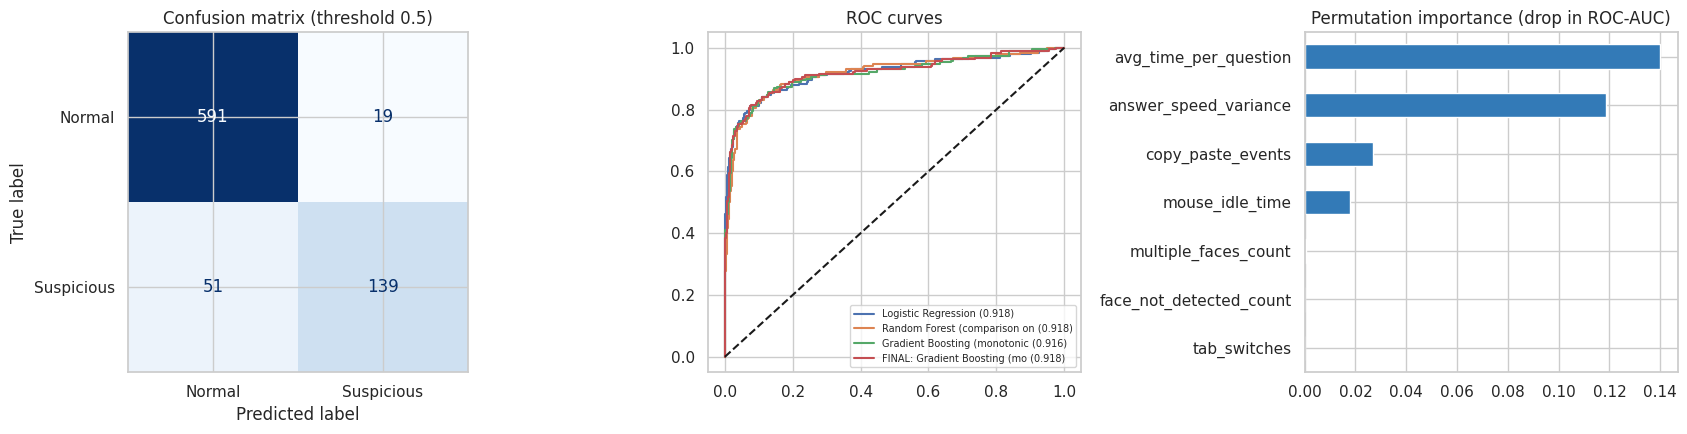

In [9]:
proba = final_A.predict_proba(Xte)[:, 1]
display(pd.DataFrame([cls_metrics(final_A, Xte, yte)], index=[best_name_A]).round(3))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay(confusion_matrix(yte, (proba >= 0.5).astype(int)), display_labels=["Normal", "Suspicious"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix (threshold 0.5)")
for n, m in {**base_models, "FINAL: " + best_name_A: final_A}.items():
    pp = m.predict_proba(Xte)[:, 1]; fpr, tpr, _ = roc_curve(yte, pp)
    ax[1].plot(fpr, tpr, label=f"{n[:28]} ({roc_auc_score(yte, pp):.3f})")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC curves"); ax[1].legend(fontsize=7)
imp = permutation_importance(final_A, Xte, yte, scoring="roc_auc", n_repeats=10, random_state=SEED)
pd.Series(imp.importances_mean, index=FEATURES_A).sort_values().plot(kind="barh", ax=ax[2], color="#337AB7")
ax[2].set_title("Permutation importance (drop in ROC-AUC)")
plt.tight_layout(); plt.show()

## 8. Choosing the decision thresholds from data (instead of guessing)
Policy of the agent:
* risk **below LOW**: release grade
* **LOW to HIGH**: release with a warning
* **above HIGH**: hold for human review

We use **out-of-fold predictions on all data**: `HIGH` is the smallest threshold where flagged sessions are at least 90% truly suspicious (so honest students are rarely held), and `LOW` is the largest threshold that still catches at least 80% of suspicious sessions at warning level or above.

In [10]:
oof = cross_val_predict(clone(final_A), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
grid_t = np.round(np.arange(0.10, 0.96, 0.05), 2)
tab = pd.DataFrame([dict(threshold=t, flagged_share=(oof >= t).mean(),
                         precision=y[oof >= t].mean() if (oof >= t).any() else np.nan,
                         recall=(oof[y == 1] >= t).mean()) for t in grid_t]).round(3)
display(tab)

hi_ok = tab[(tab.threshold >= 0.5) & (tab.precision >= 0.90) & (tab.flagged_share > 0.01)]
HIGH = float(hi_ok.threshold.min()) if len(hi_ok) else 0.7
lo_ok = tab[(tab.threshold <= 0.5) & (tab.recall >= 0.80)]
LOW = float(lo_ok.threshold.max()) if len(lo_ok) else 0.3
LOW = float(np.clip(LOW, 0.15, 0.45)); HIGH = float(np.clip(HIGH, 0.55, 0.90))
if HIGH - LOW < 0.15: LOW = round(HIGH - 0.15, 2)
print(f"Chosen thresholds -> LOW = {LOW}, HIGH = {HIGH}")

band = pd.cut(oof, [-0.01, LOW, HIGH, 1.01], labels=["RELEASE", "WARNING", "HOLD"])
print("\nWhere does each student type end up? (row percentages)")
display((pd.crosstab(sessions["student_type"], band, normalize="index") * 100).round(1))

,threshold,flagged_share,precision,recall
0,0.10,0.458,0.473,0.914
1,0.15,0.358,0.586,0.884
2,0.20,0.300,0.667,0.844
3,0.25,0.269,0.718,0.815
4,0.30,0.244,0.769,0.793
5,0.35,0.226,0.797,0.759
6,0.40,0.210,0.836,0.743
7,0.45,0.195,0.862,0.710
8,0.50,0.183,0.880,0.679
9,0.55,0.170,0.896,0.645


Chosen thresholds -> LOW = 0.25, HIGH = 0.6

Where does each student type end up? (row percentages)


col_0,RELEASE,WARNING,HOLD
student_type,,,
cheat_blatant,0.0,2.8,97.2
cheat_second_device,5.0,19.8,75.2
cheat_stealth,29.7,38.8,31.6
honest_bad_camera,87.1,12.6,0.3
honest_calm,96.1,3.8,0.2
honest_nervous,65.0,26.9,8.1


**How to read the table:** honest students should land almost entirely in RELEASE, honest-with-bad-camera students should mostly get at most a WARNING (not HOLD), and blatant cheaters should land in HOLD. Stealth cheaters are the hardest, so a share of them will only get a warning; that is a genuine limitation to mention.

## 9. Logic tests: does the model behave sensibly?

In [11]:
base = dict(tab_switches=2, face_not_detected_count=1, multiple_faces_count=0, avg_time_per_question=62,
            copy_paste_events=0, mouse_idle_time=110, answer_speed_variance=12)
sweeps = {"tab_switches": range(0, 25), "face_not_detected_count": range(0, 20), "multiple_faces_count": range(0, 8),
          "copy_paste_events": range(0, 15), "mouse_idle_time": range(0, 500, 20),
          "answer_speed_variance": range(0, 80, 4), "avg_time_per_question": range(120, 5, -5)}   # avg time goes DOWN = riskier
ok = True
for feat, vals in sweeps.items():
    risks = [final_A.predict_proba(pd.DataFrame([{**base, feat: v}])[FEATURES_A])[0, 1] for v in vals]
    mono_ok = all(b >= a - 1e-9 for a, b in zip(risks, risks[1:]))
    ok &= mono_ok
    print(f"{feat:26s} risk {risks[0]:.2f} -> {risks[-1]:.2f}   monotonic: {'PASS' if mono_ok else 'FAIL'}")
print("\nALL MONOTONIC CHECKS PASSED" if ok else "\nSome checks failed (Logistic Regression can fail on a feature with a negative learned weight)")

scen = {
 "calm honest student":      dict(tab_switches=2, face_not_detected_count=1, multiple_faces_count=0, avg_time_per_question=62, copy_paste_events=0, mouse_idle_time=110, answer_speed_variance=12),
 "nervous honest student":   dict(tab_switches=5, face_not_detected_count=2, multiple_faces_count=0, avg_time_per_question=70, copy_paste_events=1, mouse_idle_time=160, answer_speed_variance=25),
 "honest, bad webcam light": dict(tab_switches=2, face_not_detected_count=7, multiple_faces_count=0, avg_time_per_question=62, copy_paste_events=0, mouse_idle_time=120, answer_speed_variance=12),
 "phone / second screen":    dict(tab_switches=1, face_not_detected_count=6, multiple_faces_count=1, avg_time_per_question=55, copy_paste_events=0, mouse_idle_time=260, answer_speed_variance=30),
 "blatant cheater":          dict(tab_switches=14, face_not_detected_count=5, multiple_faces_count=2, avg_time_per_question=30, copy_paste_events=6, mouse_idle_time=250, answer_speed_variance=35),
}
out = []
for n, s_ in scen.items():
    r = final_A.predict_proba(pd.DataFrame([s_])[FEATURES_A])[0, 1]
    out.append((n, round(r * 100, 1), "RELEASE" if r < LOW else "WARNING" if r <= HIGH else "HOLD"))
pd.DataFrame(out, columns=["scenario", "risk %", "decision"])

tab_switches               risk 0.02 -> 0.02   monotonic: PASS
face_not_detected_count    risk 0.02 -> 0.03   monotonic: PASS
multiple_faces_count       risk 0.02 -> 0.17   monotonic: PASS
copy_paste_events          risk 0.02 -> 0.37   monotonic: PASS
mouse_idle_time            risk 0.00 -> 0.19   monotonic: PASS
answer_speed_variance      risk 0.00 -> 0.74   monotonic: PASS
avg_time_per_question      risk 0.00 -> 0.68   monotonic: PASS

ALL MONOTONIC CHECKS PASSED


,scenario,risk %,decision
0,calm honest student,1.9,RELEASE
1,nervous honest student,10.6,RELEASE
2,"honest, bad webcam light",3.4,RELEASE
3,phone / second screen,91.3,HOLD
4,blatant cheater,100.0,HOLD


# PART B: Answer grader (regression)
## 10. Data
The notebook first tries the **real Mohler short-answer dataset** (computer-science questions, human scores 0 to 5). It looks for `mohler.csv` in the Colab file panel, then tries HuggingFace. If neither works it generates a **paraphrase-based dataset**: every question has 4 key ideas, each written in 3 different ways, plus common misconceptions; a student answer is a random mix of ideas and wordings, and the score reflects how many ideas are covered (minus a penalty for a wrong claim). Unlike v1 the label comes from *meaning* (ideas covered), not from word overlap, so lexical features alone cannot solve it.

**Look at the line `DATA SOURCE` in the output and tell your teacher which one was used.**

In [12]:
def standardize(df):
    low = {c.lower().strip(): c for c in df.columns}
    def pick(*names):
        for n in names:
            if n in low: return low[n]
        for n in names:
            for lc, c in low.items():
                if n in lc: return c
        return None
    q = pick("question"); r = pick("reference_answer", "desired_answer", "instructor_answer", "ref_answer", "desired", "reference", "instructor")
    s = pick("student_answer", "student"); y = pick("score_avg", "score", "grade")
    if None in (q, r, s, y): return None
    out = df[[q, r, s, y]].copy(); out.columns = ["question", "reference_answer", "student_answer", "score"]
    out["score"] = pd.to_numeric(out["score"], errors="coerce")
    out = out.dropna()
    out = out[out["student_answer"].astype(str).str.strip() != ""]
    if out["score"].max() > 5: out["score"] = out["score"] / out["score"].max() * 5
    return out.reset_index(drop=True)

def load_real_answers():
    if os.path.exists(MOHLER_CSV):
        d = standardize(pd.read_csv(MOHLER_CSV))
        if d is not None and len(d): return d, f"uploaded file {MOHLER_CSV}"
    if not TRY_DOWNLOAD_REAL_DATA: return None, None
    try:
        try: from datasets import load_dataset, get_dataset_config_names
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets"], check=False)
            from datasets import load_dataset, get_dataset_config_names
    except Exception as e:
        print("datasets library unavailable:", e); return None, None
    for repo in HF_CANDIDATES:
        try:
            try: configs = get_dataset_config_names(repo)
            except Exception: configs = [None]
            for cfg in configs:
                dsd = load_dataset(repo, cfg) if cfg else load_dataset(repo)
                frames = [standardize(dsd[k].to_pandas()) for k in dsd]
                frames = [f for f in frames if f is not None and len(f)]
                if frames: return pd.concat(frames, ignore_index=True), f"HuggingFace dataset {repo}"
        except Exception as e:
            print(f"  could not load {repo}: {type(e).__name__}")
    return None, None

real_answers, real_src = load_real_answers()
print("Real dataset found:", real_src if real_src else "NO (using generated paraphrase dataset)")

README.md:   0%|          | 0.00/11.3k [00:00<?, ?B/s]

data/raw-oe-00001.parquet: reconstructing file:   0%|          |  0.00B /  150kB            

data/raw-oe-00001.parquet: downloading bytes:           |  0.00B            

data/raw-ce-00001.parquet: reconstructing file:   0%|          |  0.00B / 11.6kB            

data/raw-ce-00001.parquet: downloading bytes:           |  0.00B            

Generating open_ended split:   0%|          | 0/2273 [00:00<?, ? examples/s]

Generating close_ended split:   0%|          | 0/169 [00:00<?, ? examples/s]

Real dataset found: HuggingFace dataset nkazi/MohlerASAG


In [13]:
BANK = {
 "What is overfitting in machine learning?": dict(
   ideas=[["The model learns the training data too closely", "It memorizes the training set instead of learning general patterns", "A model fits the examples it was trained on too well"],
          ["It also learns the noise in the data", "It picks up random noise and irrelevant details", "Noise and outliers in the training set get fitted as well"],
          ["As a result it performs very well on training data", "Training accuracy is very high", "The error on the training set becomes tiny"],
          ["But it performs poorly on new unseen data", "Yet it fails to generalize to test data", "While accuracy on data it has never seen is low"]],
   wrong=["Overfitting means the model is too simple to learn anything", "It happens when the model is trained for too little time"]),
 "What is the purpose of a train test split?": dict(
   ideas=[["The data is divided into a training set and a test set", "The dataset is split into one part for training and one part for testing", "We separate the data into two portions, train and test"],
          ["The model is fitted using only the training set", "Training data is used to learn the model parameters", "The model learns from the training portion"],
          ["The test set is used to evaluate performance on unseen data", "Testing on held out data shows how well the model generalizes", "The held out portion gives an honest estimate of accuracy on new data"],
          ["This helps detect overfitting", "It stops us being fooled by a model that just memorized the training data", "A big gap between train and test scores reveals overfitting"]],
   wrong=["The test set is used to train the model after the training set", "Splitting the data makes the dataset larger"]),
 "What is supervised learning?": dict(
   ideas=[["The model is trained on labeled data", "Every training example comes with a known correct answer", "Inputs are paired with their target outputs"],
          ["It learns a mapping from inputs to outputs", "The goal is to learn the relationship between features and labels", "The model finds a function that maps inputs to the correct labels"],
          ["It can then predict labels for new unseen inputs", "After training it makes predictions on data without labels", "The trained model is applied to new examples to predict their outputs"],
          ["Classification and regression are the main types", "Examples are spam detection and house price prediction", "Tasks include predicting categories as well as continuous values"]],
   wrong=["Supervised learning means the data has no labels and the model finds clusters", "It requires a human to watch the model all the time"]),
 "What is gradient descent?": dict(
   ideas=[["Gradient descent is an optimization algorithm", "It is a method for minimizing a function", "It is an iterative technique used to find the minimum of a loss function"],
          ["It computes the gradient of the loss with respect to the parameters", "The slope of the loss tells which direction increases the error", "Derivatives of the loss function are calculated for every parameter"],
          ["Parameters are updated in the opposite direction of the gradient", "The weights move a small step downhill", "Each step subtracts the gradient times a learning rate"],
          ["The learning rate controls the step size", "Too large a learning rate can overshoot and too small is slow", "Steps are repeated until the loss stops decreasing"]],
   wrong=["Gradient descent is used to split data into training and test sets", "It always finds the global minimum in a single step"]),
 "What is a decision tree?": dict(
   ideas=[["A decision tree is a flowchart like model", "It has a tree structure with nodes and branches", "The model looks like an upside down tree of questions"],
          ["Each internal node tests a feature", "At every node the data is split by a condition on a feature", "Questions such as is age greater than 30 split the data"],
          ["The leaf nodes hold the final prediction", "Following the branches down ends at a leaf that gives the class or value", "A path from the root to a leaf gives the output"],
          ["Splits are chosen using measures like Gini impurity or information gain", "The best split is the one that makes the groups most pure", "The tree picks features that reduce impurity the most"]],
   wrong=["A decision tree is a neural network with many layers", "It can only be used for regression"]),
 "What is the difference between classification and regression?": dict(
   ideas=[["Classification predicts a category or class label", "The output of classification is a discrete class", "In classification the answer belongs to a fixed set of classes"],
          ["Regression predicts a continuous numeric value", "The output of regression is a real number", "Regression estimates a quantity that can take any value in a range"],
          ["Spam detection is an example of classification", "Deciding whether an email is spam or not is classification", "Labelling images as cat or dog is a typical classification task"],
          ["Predicting house prices is an example of regression", "Forecasting temperature or salary is regression", "Estimating the price of a house from its size is regression"]],
   wrong=["Classification predicts continuous numbers and regression predicts categories", "They are exactly the same task with different names"]),
 "What is cross validation?": dict(
   ideas=[["The data is divided into k equal folds", "Cross validation splits the dataset into several parts called folds", "We partition the data into k subsets"],
          ["The model is trained on k minus one folds and validated on the remaining fold", "Each fold takes a turn as the validation set", "Training and validation are repeated so every fold is used for testing once"],
          ["The scores from all folds are averaged", "The average performance gives a more reliable estimate", "Results are combined to reduce the effect of a lucky split"],
          ["It is used for model selection and hyperparameter tuning", "It helps check generalization when data is limited", "It makes better use of small datasets than a single split"]],
   wrong=["Cross validation means training the model on the test data", "It is used to increase the number of features"]),
 "What is regularization?": dict(
   ideas=[["Regularization adds a penalty term to the loss function", "A penalty on the size of the weights is added to the cost", "The loss includes an extra term that punishes complexity"],
          ["It discourages large weight values", "Weights are kept small", "The model is pushed toward smaller coefficients"],
          ["This reduces overfitting", "The model generalizes better to unseen data", "It prevents the model from fitting noise"],
          ["L1 and L2 are common types such as lasso and ridge", "Lasso uses the absolute value of weights while ridge uses squares", "L1 can make some weights exactly zero while L2 shrinks them"]],
   wrong=["Regularization means adding more training data", "It increases the model complexity to fit the data better"]),
 "What is a confusion matrix?": dict(
   ideas=[["A confusion matrix is a table that summarizes classifier performance", "It compares predicted classes with actual classes in a table", "The table shows how many predictions were right and wrong"],
          ["It contains true positives and true negatives", "Correct predictions appear as true positives and true negatives", "The diagonal holds the correctly classified cases"],
          ["It also contains false positives and false negatives", "Errors are split into false alarms and missed cases", "Wrong predictions are counted as false positives and false negatives"],
          ["Accuracy, precision and recall can be computed from it", "Metrics like the F1 score are derived from its values", "It lets us see which kinds of errors the model makes"]],
   wrong=["A confusion matrix is used to confuse the model during training", "It is only used for regression problems"]),
 "What is feature scaling and why is it used?": dict(
   ideas=[["Feature scaling puts features on a similar range", "It brings all variables to a comparable scale", "Values of different features are rescaled to similar magnitudes"],
          ["Common methods are standardization and min max normalization", "Standardization gives mean zero and unit variance", "Min max scaling squeezes values between zero and one"],
          ["It matters for distance based algorithms like KNN and SVM", "Algorithms using gradients or distances are affected by feature size", "Without scaling features with large values dominate the result"],
          ["It speeds up convergence of gradient descent", "Training becomes faster and more stable", "Tree based models usually do not need it"]],
   wrong=["Feature scaling removes the target column from the data", "It is used to increase the number of rows in the data"]),
 "What is a neural network?": dict(
   ideas=[["A neural network is made of layers of connected neurons", "It consists of an input layer, hidden layers and an output layer of nodes", "Many simple units called neurons are arranged in layers and linked together"],
          ["Each connection has a weight that is learned", "The weights on the connections are adjusted during training", "Weights decide how strongly one neuron influences the next"],
          ["Activation functions add non linearity", "Each neuron applies an activation function such as ReLU or sigmoid", "A non linear function is applied so the network can learn complex patterns"],
          ["It is trained with backpropagation and gradient descent", "Errors are propagated backwards to update the weights", "The network learns by minimizing a loss using backpropagation"]],
   wrong=["A neural network is just a database that stores answers", "It works only with images and cannot be used for text or numbers"]),
 "What is the bias variance tradeoff?": dict(
   ideas=[["Bias is the error from overly simple assumptions", "High bias means the model is too simple and underfits", "A biased model misses the real pattern in the data"],
          ["Variance is the sensitivity to small changes in the training data", "High variance means the model changes a lot with different training sets", "A high variance model fits noise and overfits"],
          ["Making a model more complex lowers bias but raises variance", "Increasing complexity reduces bias and increases variance", "Simple models have high bias and low variance while complex models have the opposite"],
          ["The goal is to find a balance that minimizes total error on new data", "We choose the model complexity that gives the best generalization", "A good model balances the two to get the lowest test error"]],
   wrong=["Bias and variance are the same thing", "The best model always has zero bias and zero variance at the same time"]),
}
FLUFF = ["This is an important topic in machine learning", "It is used in many real world applications", "We studied this concept in class", "It is a basic idea in data science", "There are many details to remember about this"]
DONT_KNOW = ["I am not sure about this", "I do not remember this topic", "I think it is something related to computers", "No idea"]

def make_generated_answers(per_q=150):
    qs = list(BANK); rows = []
    for q in qs:
        ideas, wrong = BANK[q]["ideas"], BANK[q]["wrong"]
        reference = ". ".join(v[0] for v in ideas) + "."
        for _ in range(per_q):
            k = int(rng.choice([0, 1, 2, 3, 4], p=[0.08, 0.17, 0.25, 0.25, 0.25]))
            chosen = list(rng.choice(4, size=k, replace=False)) if k else []
            parts = [ideas[i][int(rng.choice(3, p=[0.34, 0.33, 0.33]))] for i in chosen]
            rng.shuffle(parts)
            has_wrong = rng.random() < 0.20
            if has_wrong: parts.insert(int(rng.integers(0, len(parts) + 1)), str(rng.choice(wrong)))
            if not parts:   # nothing relevant: off-topic or "don't know"
                other = qs[int(rng.integers(0, len(qs)))]
                parts = [str(rng.choice(DONT_KNOW))] if (rng.random() < 0.4 or other == q) else [str(rng.choice(BANK[other]["ideas"][int(rng.integers(0, 4))]))]
            for _f in range(int(rng.choice([0, 1, 2], p=[0.5, 0.3, 0.2]))):   # padding that adds length but no ideas
                parts.insert(int(rng.integers(0, len(parts) + 1)), str(rng.choice(FLUFF)))
            text = ". ".join(parts) + "."
            if rng.random() < 0.25: text = str(rng.choice(["I think ", "Basically ", "In my opinion "])) + text[0].lower() + text[1:]
            score = 5 * k / 4 - (1.5 if has_wrong else 0) + rng.normal(0, 0.25)
            rows.append((q, reference, text, round(float(np.clip(score, 0, 5)) * 2) / 2))
    return pd.DataFrame(rows, columns=["question", "reference_answer", "student_answer", "score"])

if real_answers is not None and len(real_answers) >= 300:
    answers, DATA_SOURCE = real_answers, real_src
else:
    answers, DATA_SOURCE = make_generated_answers(), "GENERATED paraphrase dataset (12 questions x 150 answers)"
answers.to_csv("data/answers.csv", index=False)
print("DATA SOURCE:", DATA_SOURCE, "| rows:", len(answers), "| questions:", answers["question"].nunique())
answers.sample(6, random_state=3)[["student_answer", "score"]]

DATA SOURCE: HuggingFace dataset nkazi/MohlerASAG | rows: 2442 | questions: 85


,student_answer,score
1384,computers convert infix expressions to postfix...,5.0
1104,Arrays must be of a defined size... elements c...,5.0
626,Based on control statement; involve repetitio...,5.0
2117,Linked lists may be dynamically grown.,5.0
1192,"how to determine the end of the list, in basic...",5.0
2317,by-dimensional arrays are stored by row,5.0


## 11. Feature engineering: from text to numbers
`features.py` is written by this notebook and **copied into your project**, so training and the agent use identical code.

| Feature | Idea |
|---|---|
| `tfidf_cosine`, `keyword_recall`, `keyword_precision`, `jaccard`, `bigram_overlap`, `length_ratio` | Lexical features (shared words): good for answers that reuse the reference wording |
| `emb_cosine` | Cosine similarity of the **sentence embeddings** of the two answers (meaning-level similarity, catches paraphrases) |
| `emb_cov_mean`, `emb_cov_min` | **Idea coverage**: each reference sentence is matched with its most similar student sentence; the mean shows how much of the reference is covered, the minimum shows whether any idea is missing |

In [14]:
%%writefile features.py
import re
import numpy as np
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

LEXICAL = ["tfidf_cosine", "keyword_recall", "keyword_precision", "jaccard", "bigram_overlap", "length_ratio"]
EMBED = ["emb_cosine", "emb_cov_mean", "emb_cov_min"]
GRADER_FEATURES = LEXICAL + EMBED


def tokens(text):
    return re.findall(r"[a-z0-9]+", str(text).lower())


def content_words(text):
    return [w for w in tokens(text) if w not in ENGLISH_STOP_WORDS]


def split_sentences(text):
    parts = [p.strip() for p in re.split(r"(?<=[.!?;])\s+", str(text).strip()) if p.strip()]
    return parts if parts else [str(text).strip() or "empty"]


class LSAEmbedder:
    # Offline fallback embedder (TF-IDF + SVD). Much weaker than sentence-transformers.
    def __init__(self, n_components=64):
        self.n_components = n_components
        self.vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
        self.svd = TruncatedSVD(n_components=n_components, random_state=42)

    def fit(self, texts):
        X = self.vec.fit_transform(list(texts))
        self.svd.set_params(n_components=max(2, min(self.n_components, X.shape[1] - 1)))
        self.svd.fit(X)
        return self

    def encode(self, texts, normalize_embeddings=True, show_progress_bar=False, batch_size=64, **kw):
        Z = self.svd.transform(self.vec.transform(list(texts)))
        n = np.linalg.norm(Z, axis=1, keepdims=True)
        return Z / np.where(n == 0, 1, n)


class CachedEmbedder:
    # Wraps any embedder and remembers results, so each text is embedded only once.
    def __init__(self, base):
        self.base = base
        self.cache = {}

    def encode(self, texts, **kw):
        texts = [str(t) for t in texts]
        new = [t for t in dict.fromkeys(texts) if t not in self.cache]
        if new:
            E = self.base.encode(new, normalize_embeddings=True, show_progress_bar=False, batch_size=64)
            for t, e in zip(new, E):
                self.cache[t] = np.asarray(e, dtype=float)
        return np.vstack([self.cache[t] for t in texts])


def grading_features(reference, student, tfidf, embedder):
    # Compare a student answer with the reference answer; returns 9 numbers (order = GRADER_FEATURES).
    if not tokens(student):
        return [0.0] * len(GRADER_FEATURES)
    r, s = content_words(reference), content_words(student)
    rs, ss = set(r), set(s)
    inter = rs & ss
    recall = len(inter) / max(len(rs), 1)
    precision = len(inter) / max(len(ss), 1)
    jaccard = len(inter) / max(len(rs | ss), 1)
    rb, sb = set(zip(r, r[1:])), set(zip(s, s[1:]))
    bigram = len(rb & sb) / max(len(rb), 1)
    vec = tfidf.transform([str(reference), str(student)])
    tf_cos = float(vec[0].multiply(vec[1]).sum())
    length_ratio = min(len(tokens(student)) / max(len(tokens(reference)), 1), 2.0)

    ref_s, stu_s = split_sentences(reference), split_sentences(student)
    E = embedder.encode([str(reference), str(student)] + ref_s + stu_s)
    emb_cos = float(np.clip(E[0] @ E[1], 0, 1))
    R, S = E[2:2 + len(ref_s)], E[2 + len(ref_s):]
    best = np.clip((R @ S.T).max(axis=1), 0, 1)
    return [tf_cos, recall, precision, jaccard, bigram, length_ratio, emb_cos, float(best.mean()), float(best.min())]


def load_embedder(meta, models_dir):
    # Rebuild the embedder that was used in training.
    e = meta["embedder"]
    if e["type"] == "sentence-transformers":
        from sentence_transformers import SentenceTransformer
        return CachedEmbedder(SentenceTransformer(e["name"]))
    import joblib, os
    return CachedEmbedder(joblib.load(os.path.join(str(models_dir), e["file"])))

Writing features.py


In [15]:
import importlib, features
importlib.reload(features)
from features import grading_features, GRADER_FEATURES, LEXICAL, EMBED, LSAEmbedder, CachedEmbedder

# ---- choose the embedding model ----
base_embedder, EMBED_META = None, None
if not FORCE_LSA_FALLBACK:
    try:
        try: from sentence_transformers import SentenceTransformer
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers"], check=True)
            from sentence_transformers import SentenceTransformer
        base_embedder = SentenceTransformer(EMBED_NAME)
        EMBED_META = {"type": "sentence-transformers", "name": EMBED_NAME}
    except Exception as e:
        print("WARNING: could not load sentence-transformers ->", type(e).__name__, e)
if base_embedder is None:
    print("*** USING WEAK OFFLINE FALLBACK EMBEDDER (LSA). Results will be worse than with sentence-transformers. ***")
    all_txt = list(answers["reference_answer"].unique()) + list(answers["student_answer"])
    sents = [s_ for t in all_txt for s_ in features.split_sentences(t)]
    base_embedder = LSAEmbedder(64).fit(all_txt + sents)
    EMBED_META = {"type": "lsa", "file": "embedder.pkl"}
print("Embedder:", EMBED_META)

# TF-IDF for the lexical cosine (text only, no labels, so no leakage)
tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
tfidf.fit(pd.concat([answers["reference_answer"].drop_duplicates(), answers["student_answer"]]))

embedder = CachedEmbedder(base_embedder)
unique_texts = set()
for t in list(answers["reference_answer"].unique()) + list(answers["student_answer"]):
    unique_texts.add(str(t)); unique_texts.update(features.split_sentences(t))
embedder.encode(sorted(unique_texts))                          # embed everything once
F = np.array([grading_features(r, s_, tfidf, embedder) for r, s_ in zip(answers["reference_answer"], answers["student_answer"])])
feat_B = pd.DataFrame(F, columns=GRADER_FEATURES); feat_B["score"] = answers["score"].values
feat_B.head()

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedder: {'type': 'sentence-transformers', 'name': 'all-MiniLM-L6-v2'}


,tfidf_cosine,keyword_recall,keyword_precision,jaccard,bigram_overlap,length_ratio,emb_cosine,emb_cov_mean,emb_cov_min,score
0,0.036628,0.166667,0.066667,0.050000,0.0,2.000000,0.520990,0.660267,0.660267,3.5
1,0.207496,0.666667,0.235294,0.210526,0.2,2.000000,0.812363,0.826981,0.826981,5.0
2,0.382443,0.666667,0.363636,0.307692,0.6,1.636364,0.761106,0.761106,0.761106,4.0
3,0.261317,0.666667,0.200000,0.181818,0.6,2.000000,0.456788,0.639451,0.639451,5.0
4,0.032735,0.166667,0.058824,0.045455,0.0,2.000000,0.507045,0.482357,0.482357,3.0


## 12. EDA for the grader

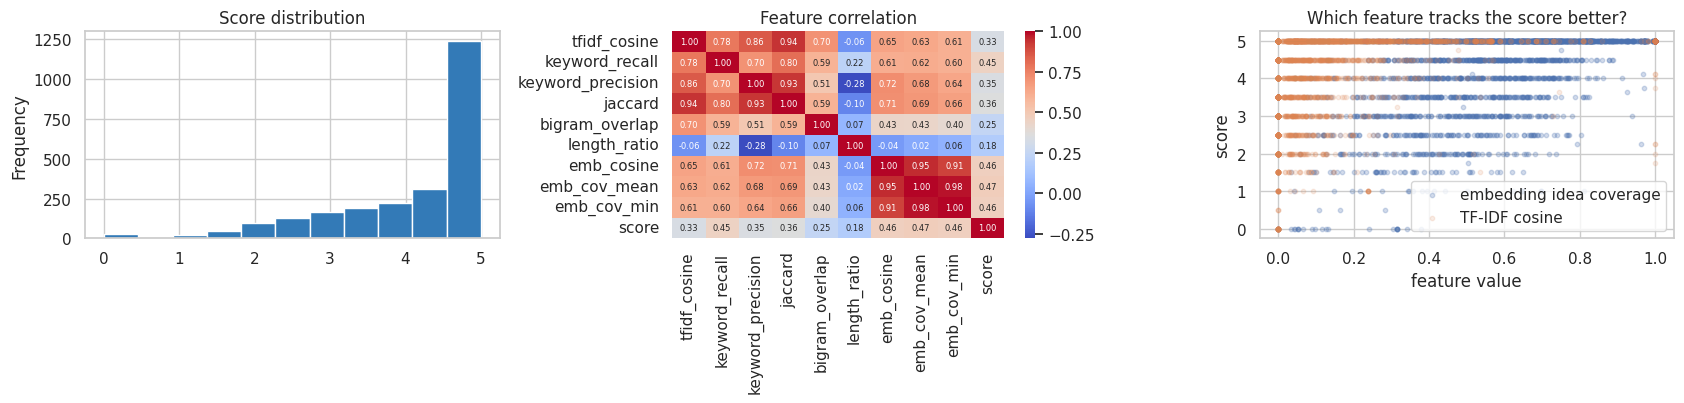

emb_cov_mean         0.473
emb_cov_min          0.463
emb_cosine           0.462
keyword_recall       0.447
jaccard              0.358
keyword_precision    0.346
tfidf_cosine         0.334
bigram_overlap       0.246
length_ratio         0.177
Name: score, dtype: float64


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
answers["score"].plot(kind="hist", bins=11, ax=ax[0], color="#337AB7"); ax[0].set_title("Score distribution")
sns.heatmap(feat_B.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1], annot_kws={"size": 6}); ax[1].set_title("Feature correlation")
ax[2].scatter(feat_B["emb_cov_mean"], feat_B["score"], alpha=0.25, s=10, label="embedding idea coverage")
ax[2].scatter(feat_B["tfidf_cosine"], feat_B["score"], alpha=0.15, s=10, label="TF-IDF cosine")
ax[2].set_xlabel("feature value"); ax[2].set_ylabel("score"); ax[2].legend(); ax[2].set_title("Which feature tracks the score better?")
plt.tight_layout(); plt.show()
print(feat_B.corr()["score"].drop("score").round(3).sort_values(ascending=False))

## 13. Split by question: can the grader handle questions it has never seen?
In v1 the same questions appeared in train and test, which is too optimistic. Here **whole questions are held out** (`GroupShuffleSplit`), which is what a teacher will face with a new exam.

In [17]:
XB = feat_B[GRADER_FEATURES]; yB = feat_B["score"]; groups = answers["question"].factorize()[0]
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(XB, yB, groups))
Xtr_b, Xte_b, ytr_b, yte_b, gtr_b = XB.iloc[tr_idx], XB.iloc[te_idx], yB.iloc[tr_idx], yB.iloc[te_idx], groups[tr_idx]
print("Train questions:", len(set(groups[tr_idx])), "| Test (unseen) questions:", len(set(groups[te_idx])), "| test rows:", len(te_idx))

def reg_metrics(model, X, y):
    p = np.clip(model.predict(X), 0, 5)
    return dict(MAE=mean_absolute_error(y, p), RMSE=mean_squared_error(y, p) ** 0.5, R2=r2_score(y, p))

reg_models = {
    "Ridge Regression":  make(Ridge(alpha=1.0)),
    "Random Forest":     make(RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED)),
    "Gradient Boosting": make(GradientBoostingRegressor(random_state=SEED)),
}
res = {}
for n, m in reg_models.items():
    m.fit(Xtr_b, ytr_b); res[n] = reg_metrics(m, Xte_b, yte_b)
pd.DataFrame(res).T.round(3)

Train questions: 63 | Test (unseen) questions: 22 | test rows: 643


,MAE,RMSE,R2
Ridge Regression,0.765,1.035,0.249
Random Forest,0.785,1.089,0.168
Gradient Boosting,0.793,1.078,0.185


## 14. Does the embedding really help? (ablation)
Same models, once with lexical features only and once with all features, tested on unseen questions.

In [18]:
abl = {}
for label, cols in [("Lexical features only", LEXICAL), ("Lexical + embedding features", GRADER_FEATURES)]:
    for n in ["Ridge Regression", "Gradient Boosting"]:
        m = clone(reg_models[n]).fit(Xtr_b[cols], ytr_b)
        abl[(label, n)] = reg_metrics(m, Xte_b[cols], yte_b)
pd.DataFrame(abl).T.round(3)

MAE   RMSE     R2
Lexical features only        Ridge Regression   0.774  1.050  0.227
                             Gradient Boosting  0.809  1.093  0.161
Lexical + embedding features Ridge Regression   0.765  1.035  0.249
                             Gradient Boosting  0.793  1.078  0.185

## 15. Tuning with GroupKFold (folds also split by question)

In [19]:
grids_B = {
    "Ridge Regression": (make(Ridge()), {"clf__alpha": [0.01, 0.1, 1, 10, 100]}),
    "Random Forest": (make(RandomForestRegressor(random_state=SEED)),
                      {"clf__n_estimators": [200], "clf__max_depth": [4, 8, None], "clf__min_samples_leaf": [2, 5]}),
    "Gradient Boosting": (make(GradientBoostingRegressor(random_state=SEED)),
                          {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [2, 3]}),
}
n_splits = min(5, len(set(gtr_b)))
tuned_B = {}
for name, (pipe, grid) in grids_B.items():
    gs = GridSearchCV(pipe, grid, scoring="neg_mean_absolute_error", cv=GroupKFold(n_splits), n_jobs=-1).fit(Xtr_b, ytr_b, groups=gtr_b)
    tuned_B[name] = gs
    print(f"{name:18s} CV MAE = {-gs.best_score_:.4f} | {gs.best_params_}")
best_name_B = min(tuned_B, key=lambda k: -tuned_B[k].best_score_)
best_model_B = tuned_B[best_name_B].best_estimator_
print("\nSelected model:", best_name_B)

Ridge Regression   CV MAE = 0.6635 | {'clf__alpha': 0.01}
Random Forest      CV MAE = 0.6570 | {'clf__max_depth': 8, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 200}
Gradient Boosting  CV MAE = 0.6638 | {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 100}

Selected model: Random Forest


## 16. Final evaluation of the grader (on unseen questions)

,MAE,RMSE,R2
Random Forest,0.777,1.07,0.197


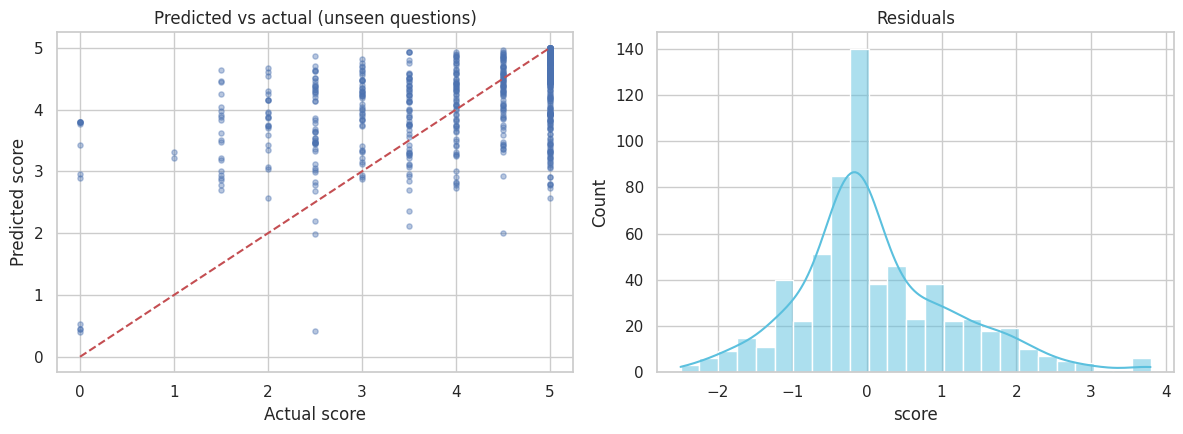

Share of answers graded within 0.5 marks of the true score: 0.485
Share within 1.0 mark: 0.684


In [20]:
display(pd.DataFrame([reg_metrics(best_model_B, Xte_b, yte_b)], index=[best_name_B]).round(3))
pred_b = np.clip(best_model_B.predict(Xte_b), 0, 5)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(yte_b, pred_b, alpha=0.4, s=14); ax[0].plot([0, 5], [0, 5], "r--")
ax[0].set_xlabel("Actual score"); ax[0].set_ylabel("Predicted score"); ax[0].set_title("Predicted vs actual (unseen questions)")
sns.histplot(pred_b - yte_b, bins=25, kde=True, ax=ax[1], color="#5BC0DE"); ax[1].set_title("Residuals")
plt.tight_layout(); plt.show()
print("Share of answers graded within 0.5 marks of the true score:", round((np.abs(pred_b - yte_b) <= 0.5).mean(), 3))
print("Share within 1.0 mark:", round((np.abs(pred_b - yte_b) <= 1.0).mean(), 3))

## 17. Real-wording paraphrase test (written by hand, never used for training)

In [21]:
test_q = "What is overfitting in machine learning?"
test_ref = ". ".join(v[0] for v in BANK[test_q]["ideas"]) + "."
cases = [
 ("Excellent, own words",   "When a model gets too attached to its training examples, even the random noise in them, it scores great on that data but is bad at predicting new data it has not seen.", "high"),
 ("Good, partly complete",  "Overfitting is when the model memorizes the training data so it does badly on new data.", "medium-high"),
 ("Half correct",           "It means the model works very well on the training data.", "medium"),
 ("Wrong claim",            "Overfitting means the model is too simple to learn anything.", "low"),
 ("Off topic",              "A decision tree has leaves and branches.", "low"),
 ("Don't know",             "I am not sure.", "low"),
]
rows = []
for name, ans_, exp in cases:
    f = grading_features(test_ref, ans_, tfidf, embedder)
    rows.append((name, exp, round(float(np.clip(best_model_B.predict(pd.DataFrame([f], columns=GRADER_FEATURES))[0], 0, 5)), 2)))
pd.DataFrame(rows, columns=["case", "expected", "predicted score /5"])

,case,expected,predicted score /5
0,"Excellent, own words",high,4.56
1,"Good, partly complete",medium-high,3.56
2,Half correct,medium,3.77
3,Wrong claim,low,3.66
4,Off topic,low,2.91
5,Don't know,low,2.05


## 18. Save everything for the project
Besides the models, `meta.json` stores: thresholds, normal statistics (used to explain *why* a session is risky), valid input ranges (the agent clips values outside them), and **guardrails**. A guardrail is a plain rule: if a count is higher than 99.5% of honest students ever reached (for example a very large number of tab switches), the decision can never be better than WARNING, even if the model is unsure. This keeps the system explainable and protects against inputs far outside the training range.

In [22]:
normal = sessions[sessions["suspicious"] == 0][FEATURES_A]
honest = sessions[sessions["student_type"].str.startswith("honest")]
GUARD_FEATURES = ["tab_switches", "face_not_detected_count", "multiple_faces_count", "copy_paste_events"]
meta = {
    "guardrails": {c: float(np.ceil(honest[c].quantile(0.995))) for c in GUARD_FEATURES},
    "cheat_features": FEATURES_A, "grader_features": GRADER_FEATURES,
    "normal_mean": normal.mean().round(3).to_dict(), "normal_std": normal.std().round(3).to_dict(),
    "clip_bounds": {c: [float(sessions[c].quantile(0.001)), float(sessions[c].quantile(0.999)) * 1.5] for c in FEATURES_A},
    "cheat_model": best_name_A + (" + calibration" if use_cal else ""), "grader_model": best_name_B,
    "thresholds": {"low": LOW, "high": HIGH},
    "embedder": EMBED_META, "data_source_grader": DATA_SOURCE,
    "definitions": {"answer_speed_variance": "standard deviation of seconds spent per question",
                    "reference_exam": "about 20 questions / 20 minutes; counts scale with exam length"},
    "versions": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__, "numpy": np.__version__,
                 "pandas": pd.__version__, "joblib": joblib.__version__},
}
# Final models are refitted on ALL data (test metrics above were measured before this step)
final_A_deploy = clone(final_A).fit(X, y)
best_B_deploy = clone(best_model_B).fit(XB, yB)

joblib.dump(final_A_deploy, "models/cheat_model.pkl")
joblib.dump(best_B_deploy, "models/grader_model.pkl")
joblib.dump(tfidf, "models/tfidf.pkl")
if EMBED_META["type"] == "lsa": joblib.dump(base_embedder, "models/embedder.pkl")
json.dump(meta, open("models/meta.json", "w"), indent=2)
print(sorted(os.listdir("models")))

['cheat_model.pkl', 'grader_model.pkl', 'meta.json', 'tfidf.pkl']


## 19. Self-test: load the saved files exactly as the agent will, then run the full flow

In [23]:
from features import load_embedder
cheat = joblib.load("models/cheat_model.pkl"); grader = joblib.load("models/grader_model.pkl")
tf_ = joblib.load("models/tfidf.pkl"); m_ = json.load(open("models/meta.json")); emb_ = load_embedder(m_, "models")

ans1 = "When a model gets too attached to its training examples, even the random noise in them, it scores great on that data but is bad at predicting new data it has not seen."
f = grading_features(test_ref, ans1, tf_, emb_)
grade = float(np.clip(grader.predict(pd.DataFrame([f], columns=GRADER_FEATURES))[0], 0, 5))
for name, s_ in [("calm honest", scen["calm honest student"]), ("blatant cheater", scen["blatant cheater"])]:
    risk = float(cheat.predict_proba(pd.DataFrame([s_])[FEATURES_A])[0, 1])
    d = "RELEASE" if risk < m_["thresholds"]["low"] else "RELEASE_WITH_WARNING" if risk <= m_["thresholds"]["high"] else "HOLD_FOR_REVIEW"
    print(f"{name:16s} grade {grade:.2f}/5 | risk {risk:.0%} | decision {d}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

calm honest      grade 4.60/5 | risk 1% | decision RELEASE
blatant cheater  grade 4.60/5 | risk 100% | decision HOLD_FOR_REVIEW


## 20. Package for download
Creates `exam_models.zip` (models, features.py, data and the exact library versions). Unzip it into your project folder and replace the old `models/`, `features.py` and `data/`.

In [24]:
reqs = [f"scikit-learn=={sklearn.__version__}", f"numpy=={np.__version__}", f"pandas=={pd.__version__}", f"joblib=={joblib.__version__}"]
if EMBED_META["type"] == "sentence-transformers":
    import sentence_transformers; reqs.append(f"sentence-transformers=={sentence_transformers.__version__}")
open("requirements_models.txt", "w").write("\n".join(reqs) + "\n")
print("Install these on your laptop BEFORE running the project (so the saved models load correctly):\n  pip install " + " ".join(reqs))

shutil.rmtree("exam_models", ignore_errors=True); os.makedirs("exam_models")
for p in ["models", "data"]: shutil.copytree(p, f"exam_models/{p}")
for p in ["features.py", "requirements_models.txt"]: shutil.copy(p, f"exam_models/{p}")
shutil.make_archive("exam_models", "zip", "exam_models")
try:
    from google.colab import files
    files.download("exam_models.zip")
except ImportError:
    print("Not running in Colab: exam_models.zip was created in the current folder.")

Install these on your laptop BEFORE running the project (so the saved models load correctly):
  pip install scikit-learn==1.6.1 numpy==2.1.3 pandas==2.2.3 joblib==1.6.0 sentence-transformers==5.7.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 21. Summary and limitations
* **Proctor:** calibrated, monotonic gradient boosting with data-driven thresholds. Results come from *simulated* sessions, so real-world performance must be re-checked on real logs.
* **Grader:** embeddings plus lexical features, evaluated on unseen questions. If the real Mohler data was used, scores come from human graders; if the generated dataset was used, state that clearly.
* **Stealth cheating** (small signals) and **honest students with technical problems** are inherently ambiguous: that is why risk is a probability, the middle band only warns, and HOLD always goes to a human.
* Counts scale with exam length. The training data assumes an exam of about 20 questions; very short exams produce smaller counts and therefore lower risk.
* A proctoring model can be biased (lighting, camera quality, disabilities). Fairness testing is required before any real use.